In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
DATA_PATH = Path("../data/interim/weekly_demand_500_articles.csv")

weekly_dataset = pd.read_csv(
    DATA_PATH,
    dtype={"article_id": "string"}
)

weekly_dataset["week_start"] = pd.to_datetime(
    weekly_dataset["week_start"]
)

weekly_dataset = weekly_dataset.sort_values(
    ["article_id", "week_start"]
).reset_index(drop=True)

print("Dataset loaded successfully!")

print("Total records:", len(weekly_dataset))
print("Unique articles:", weekly_dataset["article_id"].nunique())

display(weekly_dataset.head())

Dataset loaded successfully!
Total records: 20308
Unique articles: 500


,article_id,week_start,weekly_demand,product_type_name,product_group_name,colour_group_name,department_name,index_name,section_name,garment_group_name
0,0189616032,2019-12-09,20,Leggings/Tights,Garment Lower body,Black,Basic 1,Divided,Divided Basics,Jersey Basic
1,0189616032,2019-12-16,45,Leggings/Tights,Garment Lower body,Black,Basic 1,Divided,Divided Basics,Jersey Basic
2,0189616032,2019-12-23,38,Leggings/Tights,Garment Lower body,Black,Basic 1,Divided,Divided Basics,Jersey Basic
3,0189616032,2019-12-30,29,Leggings/Tights,Garment Lower body,Black,Basic 1,Divided,Divided Basics,Jersey Basic
4,0189616032,2020-01-06,32,Leggings/Tights,Garment Lower body,Black,Basic 1,Divided,Divided Basics,Jersey Basic


In [4]:
#Aggregate weekly demand
weekly_total_demand = (
    weekly_dataset
    .groupby("week_start")["weekly_demand"]
    .sum()
    .reset_index()
)

print("Total calendar weeks:", len(weekly_total_demand))

display(weekly_total_demand.head())

Total calendar weeks: 106


,week_start,weekly_demand
0,2018-09-17,780
1,2018-09-24,1985
2,2018-10-01,1323
3,2018-10-08,1672
4,2018-10-15,2285


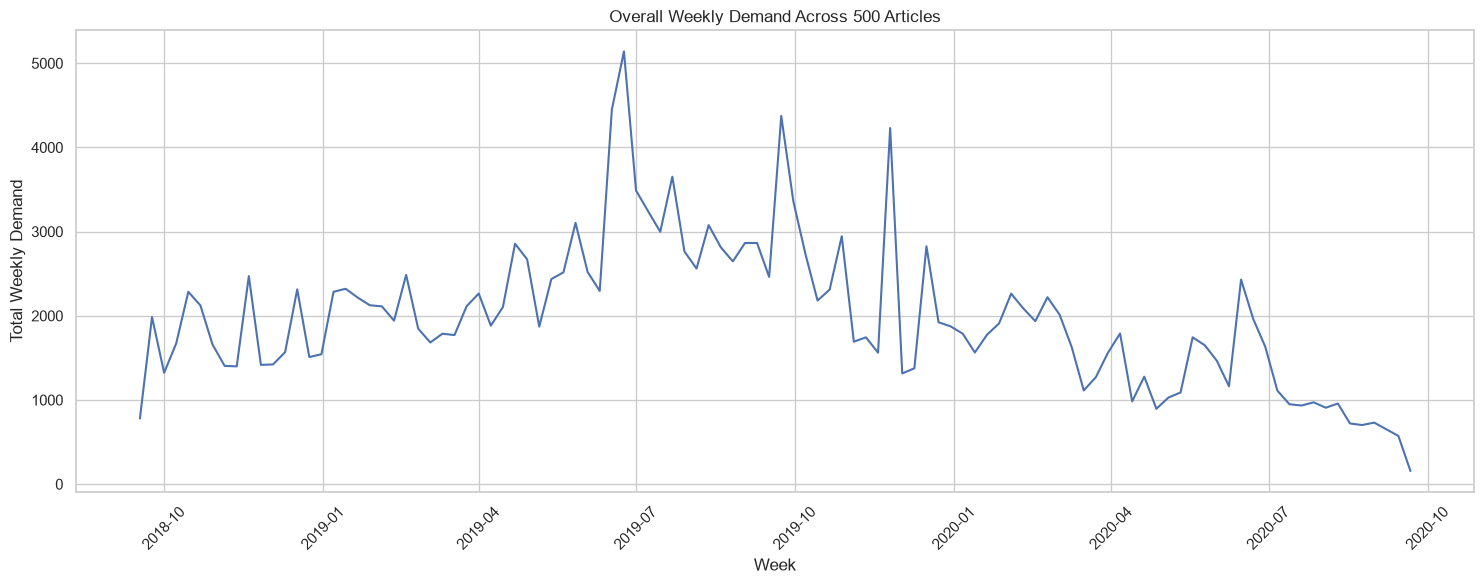

In [5]:
#plot weekly demand
plt.figure(figsize=(15, 6))

plt.plot(
    weekly_total_demand["week_start"],
    weekly_total_demand["weekly_demand"],
    linewidth=1.5
)

plt.title("Overall Weekly Demand Across 500 Articles")
plt.xlabel("Week")
plt.ylabel("Total Weekly Demand")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [7]:
#calculate demand stats
demand_statistics = weekly_dataset["weekly_demand"].describe()

print("Weekly Demand Distribution:")
display(demand_statistics)

Weekly Demand Distribution:


count    20308.000000
mean        10.397725
std         27.474981
min          0.000000
25%          0.000000
50%          2.000000
75%          8.000000
max       1096.000000
Name: weekly_demand, dtype: float64

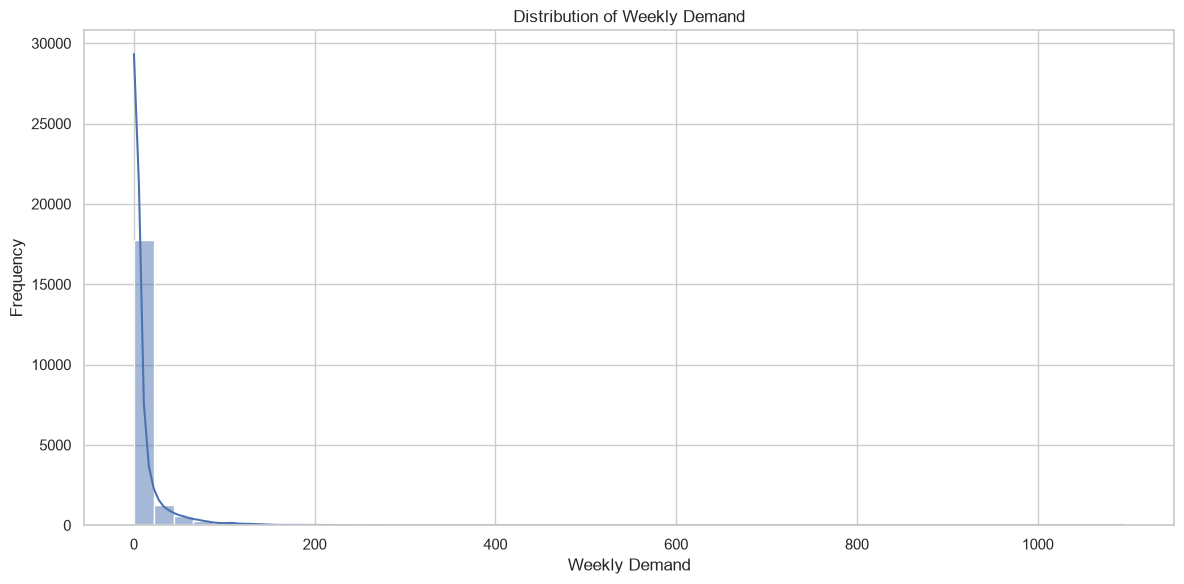

In [8]:
#plot demand distribution
plt.figure(figsize=(12, 6))

sns.histplot(
    data=weekly_dataset,
    x="weekly_demand",
    bins=50,
    kde=True
)

plt.title("Distribution of Weekly Demand")
plt.xlabel("Weekly Demand")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

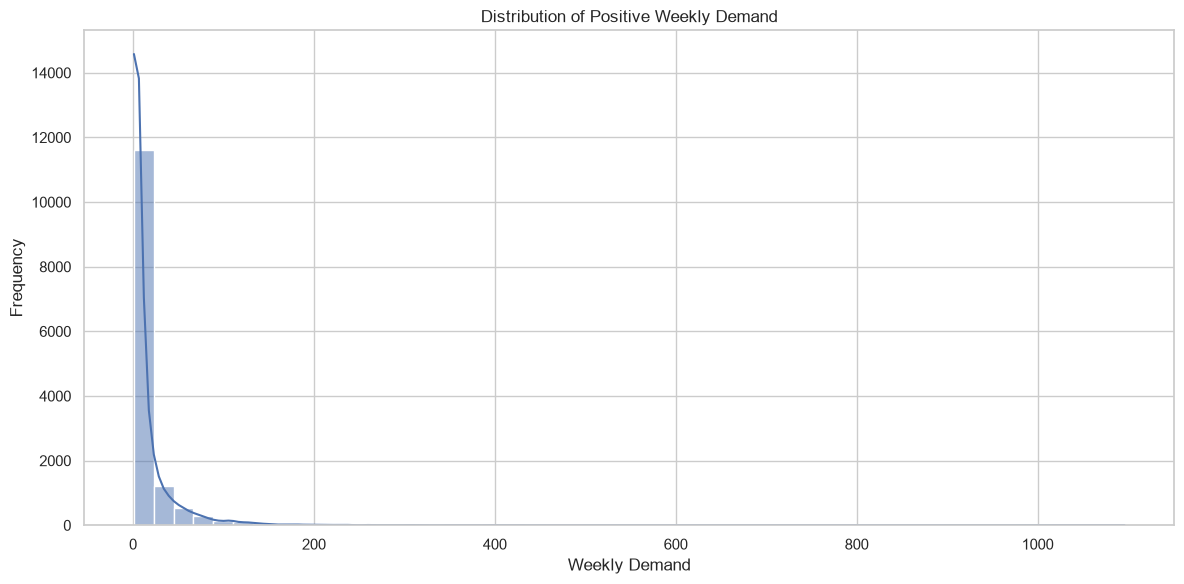

In [9]:
# + demand distribution
positive_demand = weekly_dataset[
    weekly_dataset["weekly_demand"] > 0
]

plt.figure(figsize=(12, 6))

sns.histplot(
    data=positive_demand,
    x="weekly_demand",
    bins=50,
    kde=True
)

plt.title("Distribution of Positive Weekly Demand")
plt.xlabel("Weekly Demand")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [10]:
# calculate 0 demand stats
total_records = len(weekly_dataset)

zero_demand_records = (
    weekly_dataset["weekly_demand"] == 0
).sum()

positive_demand_records = (
    weekly_dataset["weekly_demand"] > 0
).sum()

zero_percentage = (
    zero_demand_records / total_records
) * 100

positive_percentage = (
    positive_demand_records / total_records
) * 100

print("Total records:", total_records)

print("Zero-demand records:", zero_demand_records)
print("Positive-demand records:", positive_demand_records)

print(f"Zero-demand percentage: {zero_percentage:.2f}%")
print(f"Positive-demand percentage: {positive_percentage:.2f}%")

Total records: 20308
Zero-demand records: 6262
Positive-demand records: 14046
Zero-demand percentage: 30.84%
Positive-demand percentage: 69.16%


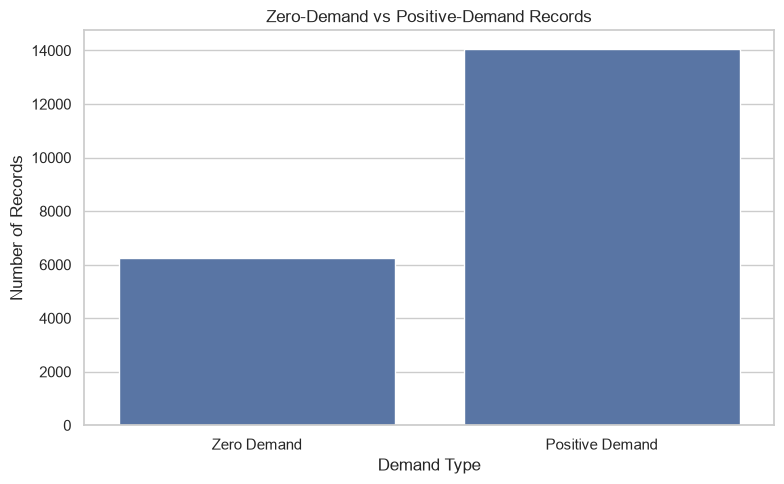

In [11]:
#visualize 0 vs + demand
demand_counts = pd.DataFrame({
    "Demand Type": ["Zero Demand", "Positive Demand"],
    "Records": [
        zero_demand_records,
        positive_demand_records
    ]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=demand_counts,
    x="Demand Type",
    y="Records"
)

plt.title("Zero-Demand vs Positive-Demand Records")
plt.xlabel("Demand Type")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [12]:
#calculate article level stats
article_statistics = (
    weekly_dataset
    .groupby("article_id")
    .agg(
        total_demand=("weekly_demand", "sum"),
        average_demand=("weekly_demand", "mean"),
        median_demand=("weekly_demand", "median"),
        std_demand=("weekly_demand", "std"),
        zero_demand_weeks=(
            "weekly_demand",
            lambda x: (x == 0).sum()
        ),
        active_weeks=(
            "weekly_demand",
            lambda x: (x > 0).sum()
        ),
        total_weeks=("weekly_demand", "count")
    )
    .reset_index()
)

article_statistics["zero_demand_percentage"] = (
    article_statistics["zero_demand_weeks"]
    / article_statistics["total_weeks"]
) * 100

display(article_statistics.head(10))

,article_id,total_demand,average_demand,median_demand,std_demand,zero_demand_weeks,active_weeks,total_weeks,zero_demand_percentage
0,0189616032,574,13.666667,11.5,12.992806,6,36,42,14.285714
1,0240840032,1,1.000000,1.0,NaN,0,1,1,0.000000
2,0266875015,8,1.333333,1.0,1.032796,1,5,6,16.666667
3,0318914016,1,1.000000,1.0,NaN,0,1,1,0.000000
4,0327144031,37,0.569231,0.0,1.435806,47,18,65,72.307692
5,0335896020,1,1.000000,1.0,NaN,0,1,1,0.000000
6,0351933052,714,9.272727,2.0,12.765740,29,48,77,37.662338
7,0387348017,1,1.000000,1.0,NaN,0,1,1,0.000000
8,0387843037,1,1.000000,1.0,NaN,0,1,1,0.000000
9,0395864046,17,0.485714,0.0,1.651584,30,5,35,85.714286


In [13]:
#identify highets demand articles
top_articles = article_statistics.sort_values(
    by="total_demand",
    ascending=False
).head(10)

display(top_articles)

,article_id,total_demand,average_demand,median_demand,std_demand,zero_demand_weeks,active_weeks,total_weeks,zero_demand_percentage
184,0656763001,9079,86.466667,14.0,170.114388,9,96,105,8.571429
11,0399256023,6511,61.424528,56.0,37.454976,6,100,106,5.660377
60,0542464001,5758,54.838095,40.0,42.503422,0,105,105,0.000000
94,0569984001,3838,36.207547,36.0,22.376313,0,106,106,0.000000
386,0770315006,3408,54.967742,53.5,31.063113,0,62,62,0.000000
80,0559634002,3299,35.473118,6.0,47.551709,12,81,93,12.903226
55,0536139012,3128,31.280000,23.0,51.714265,19,81,100,19.000000
237,0692721002,3043,32.720430,5.0,42.417789,9,84,93,9.677419
421,0794819001,2832,44.250000,10.5,65.016481,8,56,64,12.500000
285,0720635008,2605,36.180556,15.5,53.178500,3,69,72,4.166667


In [14]:
#articles with highets zero demand %
intermittent_articles = article_statistics.sort_values(
    by="zero_demand_percentage",
    ascending=False
).head(10)

display(intermittent_articles)

,article_id,total_demand,average_demand,median_demand,std_demand,zero_demand_weeks,active_weeks,total_weeks,zero_demand_percentage
13,0411013002,6,0.092308,0.0,0.341096,60,5,65,92.307692
102,0576224003,2,0.083333,0.0,0.282330,22,2,24,91.666667
63,0548738001,8,0.085106,0.0,0.280536,86,8,94,91.489362
85,0563156001,2,0.111111,0.0,0.323381,16,2,18,88.888889
422,0794910001,9,0.180000,0.0,0.481918,43,7,50,86.000000
387,0770691006,9,0.428571,0.0,1.247855,18,3,21,85.714286
260,0705671003,9,0.428571,0.0,1.535299,18,3,21,85.714286
9,0395864046,17,0.485714,0.0,1.651584,30,5,35,85.714286
104,0578176001,10,0.476190,0.0,1.749830,18,3,21,85.714286
131,0608334001,5,0.250000,0.0,0.638666,17,3,20,85.000000


In [15]:
# Select three articles with the highest total demand (select representative articles)
selected_articles = (
    article_statistics
    .nlargest(3, "total_demand")["article_id"]
    .tolist()
)

print("Selected articles:", selected_articles)

Selected articles: ['0656763001', '0399256023', '0542464001']


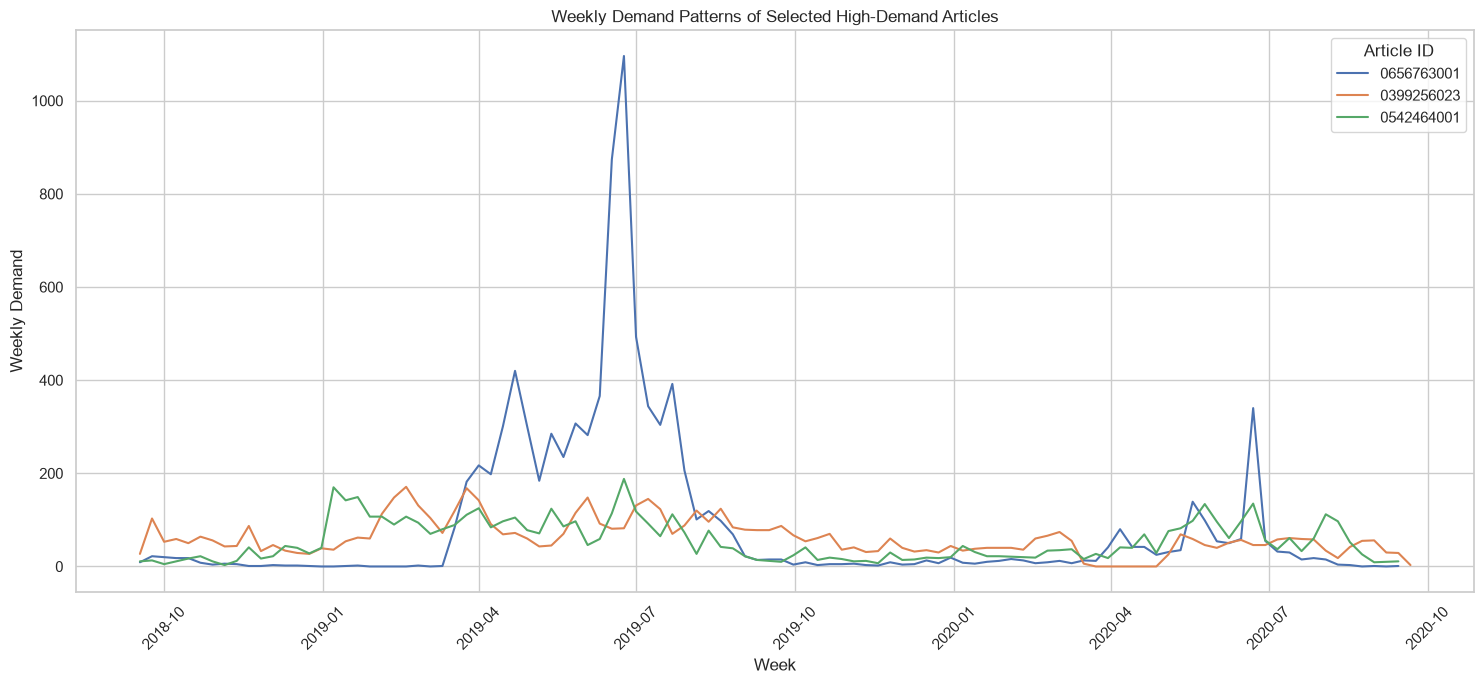

In [16]:
#plot individual demand patterns
plt.figure(figsize=(15, 7))

for article in selected_articles:

    article_data = weekly_dataset[
        weekly_dataset["article_id"] == article
    ]

    plt.plot(
        article_data["week_start"],
        article_data["weekly_demand"],
        label=str(article),
        linewidth=1.5
    )

plt.title("Weekly Demand Patterns of Selected High-Demand Articles")
plt.xlabel("Week")
plt.ylabel("Weekly Demand")

plt.legend(title="Article ID")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [17]:
#demand by product group
product_group_demand = (
    weekly_dataset
    .groupby("product_group_name")
    .agg(
        total_demand=("weekly_demand", "sum"),
        average_weekly_demand=("weekly_demand", "mean"),
        article_count=("article_id", "nunique")
    )
    .reset_index()
    .sort_values(
        by="total_demand",
        ascending=False
    )
)

display(product_group_demand)

,product_group_name,total_demand,average_weekly_demand,article_count
3,Garment Upper body,74247,9.655007,204
2,Garment Lower body,49766,11.338802,99
1,Garment Full body,31667,11.049197,59
7,Swimwear,20367,20.225422,15
8,Underwear,18383,13.301737,31
0,Accessories,8692,4.546025,56
4,Nightwear,6318,15.042857,12
5,Shoes,1044,3.378641,14
6,Socks & Tights,673,2.021021,10


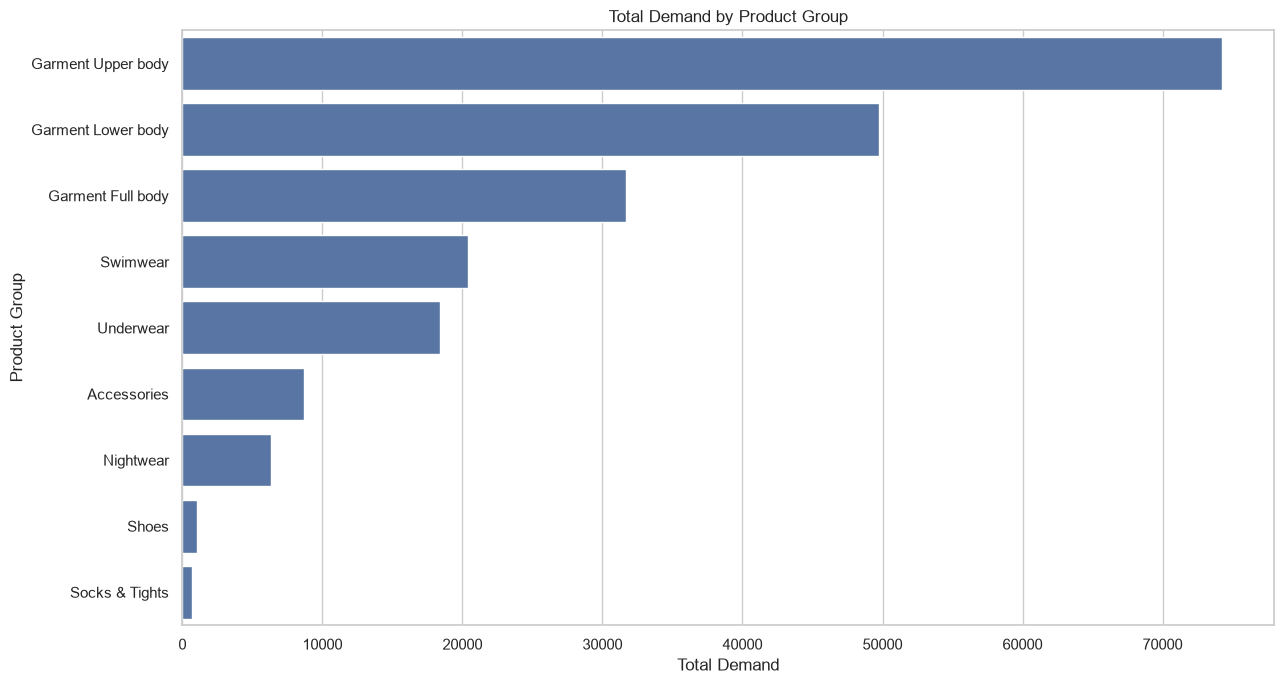

In [18]:
#visualize product group demand
plt.figure(figsize=(13, 7))

sns.barplot(
    data=product_group_demand,
    x="total_demand",
    y="product_group_name"
)

plt.title("Total Demand by Product Group")
plt.xlabel("Total Demand")
plt.ylabel("Product Group")

plt.tight_layout()
plt.show()

In [19]:
#identify article activity periods
article_activity = (
    weekly_dataset
    .groupby("article_id")
    .agg(
        first_active_week=("week_start", "min"),
        last_active_week=("week_start", "max"),
        total_weeks=("week_start", "count"),
        total_demand=("weekly_demand", "sum")
    )
    .reset_index()
)

print("Article activity summary:")

display(
    article_activity.sort_values(
        by="last_active_week"
    ).head(20)
)

Article activity summary:


,article_id,first_active_week,last_active_week,total_weeks,total_demand
30,0496507003,2018-09-17,2018-09-17,1,1
199,0668637001,2018-09-17,2018-09-17,1,1
62,0547391005,2018-09-24,2018-09-24,1,1
64,0550326001,2018-09-24,2018-09-24,1,1
65,0550801001,2018-09-24,2018-09-24,1,1
158,0631870001,2018-09-17,2018-09-24,2,3
105,0578369001,2018-09-24,2018-09-24,1,1
203,0671599003,2018-09-24,2018-09-24,1,1
43,0515357002,2018-09-24,2018-10-01,2,2
5,0335896020,2018-10-01,2018-10-01,1,1


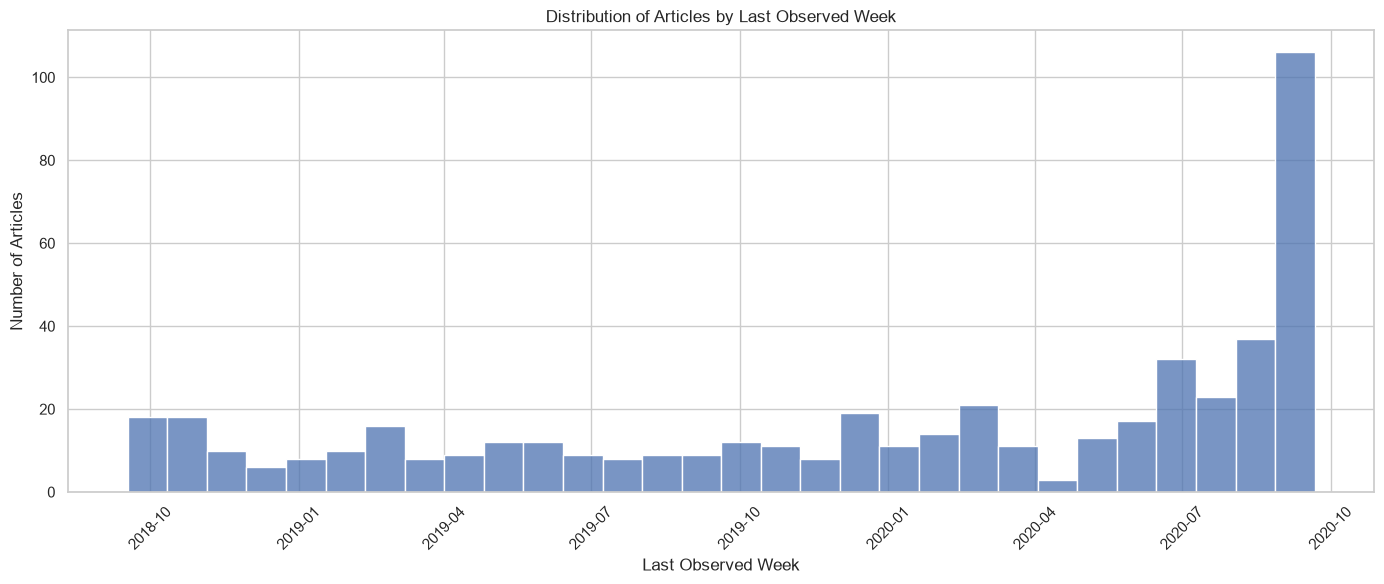

In [20]:
#analyse last observed sales period
plt.figure(figsize=(14, 6))

sns.histplot(
    data=article_activity,
    x="last_active_week",
    bins=30
)

plt.title("Distribution of Articles by Last Observed Week")
plt.xlabel("Last Observed Week")
plt.ylabel("Number of Articles")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [21]:
#count articles by last observed periods
training_end = pd.Timestamp("2020-02-17")
validation_end = pd.Timestamp("2020-06-08")

article_activity["last_active_period"] = np.select(
    [
        article_activity["last_active_week"] <= training_end,
        article_activity["last_active_week"] <= validation_end
    ],
    [
        "Training period",
        "Validation period"
    ],
    default="Testing period"
)

print("Articles grouped by last observed period:")

display(
    article_activity["last_active_period"]
    .value_counts()
)

Articles grouped by last observed period:


last_active_period
Training period      245
Testing period       198
Validation period     57
Name: count, dtype: int64

In [22]:
#save EDA results
OUTPUT_PATH = Path("../data/interim")

OUTPUT_PATH.mkdir(
    parents=True,
    exist_ok=True
)

article_statistics.to_csv(
    OUTPUT_PATH / "article_demand_statistics.csv",
    index=False
)

product_group_demand.to_csv(
    OUTPUT_PATH / "product_group_demand_statistics.csv",
    index=False
)

print("EDA statistics saved successfully!")

EDA statistics saved successfully!


In [23]:
#last week with + demand
article_activity_check = (
    weekly_dataset
    .groupby("article_id")
    .agg(
        first_recorded_week=("week_start", "min"),
        last_recorded_week=("week_start", "max"),
        first_positive_week=(
            "week_start",
            lambda x: x[
                weekly_dataset.loc[x.index, "weekly_demand"] > 0
            ].min()
        ),
        last_positive_week=(
            "week_start",
            lambda x: x[
                weekly_dataset.loc[x.index, "weekly_demand"] > 0
            ].max()
        ),
        total_records=("weekly_demand", "count"),
        positive_weeks=(
            "weekly_demand",
            lambda x: (x > 0).sum()
        )
    )
    .reset_index()
)

display(article_activity_check.head(20))

,article_id,first_recorded_week,last_recorded_week,first_positive_week,last_positive_week,total_records,positive_weeks
0,0189616032,2019-12-09,2020-09-21,2019-12-09,2020-09-21,42,36
1,0240840032,2018-10-29,2018-10-29,2018-10-29,2018-10-29,1,1
2,0266875015,2018-12-17,2019-01-21,2018-12-17,2019-01-21,6,5
3,0318914016,2018-10-22,2018-10-22,2018-10-22,2018-10-22,1,1
4,0327144031,2018-09-24,2019-12-16,2018-09-24,2019-12-16,65,18
5,0335896020,2018-10-01,2018-10-01,2018-10-01,2018-10-01,1,1
6,0351933052,2019-01-07,2020-06-22,2019-01-07,2020-06-22,77,48
7,0387348017,2018-10-29,2018-10-29,2018-10-29,2018-10-29,1,1
8,0387843037,2018-12-03,2018-12-03,2018-12-03,2018-12-03,1,1
9,0395864046,2018-09-24,2019-05-20,2018-09-24,2019-05-20,35,5


In [24]:
#check weekly continuity
weekly_dataset = weekly_dataset.sort_values(
    ["article_id", "week_start"]
)

weekly_dataset["days_between_records"] = (
    weekly_dataset
    .groupby("article_id")["week_start"]
    .diff()
    .dt.days
)

gap_summary = weekly_dataset[
    weekly_dataset["days_between_records"].notna()
]["days_between_records"].value_counts().sort_index()

print("Days between consecutive article records:")
display(gap_summary)

invalid_gaps = weekly_dataset[
    weekly_dataset["days_between_records"].notna()
    & (weekly_dataset["days_between_records"] != 7)
]

print("Number of non-seven-day gaps:", len(invalid_gaps))

display(invalid_gaps.head(10))

Days between consecutive article records:


days_between_records
7.0    19808
Name: count, dtype: int64

Number of non-seven-day gaps: 0


,article_id,week_start,weekly_demand,product_type_name,product_group_name,colour_group_name,department_name,index_name,section_name,garment_group_name,days_between_records


In [25]:
#calculate demand intermittency indicators
def calculate_intermittency(group):

    positive = group[group > 0]

    total_periods = len(group)
    nonzero_periods = len(positive)

    if nonzero_periods == 0:
        return pd.Series({
            "ADI": np.nan,
            "CV_squared": np.nan
        })

    adi = total_periods / nonzero_periods

    if positive.mean() == 0:
        cv_squared = np.nan

    elif nonzero_periods < 2:
        cv_squared = np.nan

    else:
        cv_squared = (
            positive.std() / positive.mean()
        ) ** 2

    return pd.Series({
        "ADI": adi,
        "CV_squared": cv_squared
    })


intermittency_statistics = (
    weekly_dataset
    .groupby("article_id")["weekly_demand"]
    .apply(calculate_intermittency)
    .unstack()
    .reset_index()
)

display(
    intermittency_statistics.sort_values(
        by="ADI",
        ascending=False
    ).head(15)
)

,article_id,ADI,CV_squared
13,0411013002,13.000000,0.138889
102,0576224003,12.000000,0.000000
63,0548738001,11.750000,0.000000
85,0563156001,9.000000,0.000000
422,0794910001,7.142857,0.144033
387,0770691006,7.000000,0.444444
260,0705671003,7.000000,1.333333
9,0395864046,7.000000,0.934256
104,0578176001,7.000000,1.470000
131,0608334001,6.666667,0.120000


In [26]:
#calculate article level demand comparison
article_product_summary = (
    weekly_dataset
    .groupby(
        ["article_id", "product_group_name"]
    )
    .agg(
        total_demand=("weekly_demand", "sum"),
        observed_weeks=("weekly_demand", "count")
    )
    .reset_index()
)

article_product_summary["average_demand_per_week"] = (
    article_product_summary["total_demand"]
    / article_product_summary["observed_weeks"]
)

product_comparison = (
    article_product_summary
    .groupby("product_group_name")
    .agg(
        article_count=("article_id", "nunique"),
        total_demand=("total_demand", "sum"),
        average_demand_per_article=(
            "average_demand_per_week", "mean"
        ),
        median_demand_per_article=(
            "average_demand_per_week", "median"
        )
    )
    .reset_index()
    .sort_values(
        by="average_demand_per_article",
        ascending=False
    )
)

display(product_comparison)

,product_group_name,article_count,total_demand,average_demand_per_article,median_demand_per_article
7,Swimwear,15,20367,19.012018,12.427083
8,Underwear,31,18383,10.998780,5.925000
1,Garment Full body,59,31667,9.787590,4.195122
4,Nightwear,12,6318,8.820287,5.475783
2,Garment Lower body,99,49766,8.175563,3.133333
3,Garment Upper body,204,74247,7.701499,3.443860
0,Accessories,56,8692,3.840107,3.664815
5,Shoes,14,1044,3.141490,1.569672
6,Socks & Tights,10,673,2.371600,1.222222


In [27]:
#summarise article eligibility
eligibility_summary = article_statistics.copy()

eligibility_summary["eligibility_group"] = np.select(
    [
        eligibility_summary["active_weeks"] < 5,
        eligibility_summary["active_weeks"] < 10,
        eligibility_summary["active_weeks"] < 20
    ],
    [
        "Very limited positive history",
        "Limited positive history",
        "Moderate positive history"
    ],
    default="More extensive positive history"
)

print("Article history summary:")

display(
    eligibility_summary["eligibility_group"]
    .value_counts()
)

print("\nDetailed article eligibility:")
display(
    eligibility_summary[
        [
            "article_id",
            "active_weeks",
            "total_weeks",
            "zero_demand_percentage",
            "eligibility_group"
        ]
    ].head(20)
)

Article history summary:


eligibility_group
More extensive positive history    298
Moderate positive history           86
Very limited positive history       76
Limited positive history            40
Name: count, dtype: int64


Detailed article eligibility:


,article_id,active_weeks,total_weeks,zero_demand_percentage,eligibility_group
0,0189616032,36,42,14.285714,More extensive positive history
1,0240840032,1,1,0.000000,Very limited positive history
2,0266875015,5,6,16.666667,Limited positive history
3,0318914016,1,1,0.000000,Very limited positive history
4,0327144031,18,65,72.307692,Moderate positive history
5,0335896020,1,1,0.000000,Very limited positive history
6,0351933052,48,77,37.662338,More extensive positive history
7,0387348017,1,1,0.000000,Very limited positive history
8,0387843037,1,1,0.000000,Very limited positive history
9,0395864046,5,35,85.714286,Limited positive history
